# Checking Muninn with astropy

Muninn reads SPHEREx frames in the browser with its own FITS, WCS and Rice code. This notebook
checks its key numbers with the standard Python tools, following the two tutorials the
challenge's Resources tab names:

- the [SPHEREx Tutorial Notebooks](https://caltech-ipac.github.io/irsa-tutorials/spherex/) (IRSA SIA, reading Level-2 frames from the S3 mirror);
- the CSA's [NEOSSat Data Tutorial](https://github.com/asc-csa/NEOSSAT_Tutorial) (finding and opening NEOSSat frames at CADC).

Field: the Atala field, RA 13.4194, Dec +3.8459, detector D2 (1.10–1.65 µm).

In [1]:
import tempfile
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.time import Time
from astropy.visualization import AsinhStretch, ImageNormalize, ZScaleInterval
from astropy.wcs import WCS
import pyvo

FIELD = SkyCoord(13.4194, 3.8459, unit="deg")

## 1. Find the frames (IRSA SIA, collection `spherex_dr1`)

In [2]:
sia = pyvo.dal.SIA2Service("https://irsa.ipac.caltech.edu/SIA")
frames = sia.search(pos=(FIELD, 0.006 * u.deg), collection="spherex_dr1").to_table()
science = frames[frames["dataproduct_subtype"] == "science"]
d2 = science[science["energy_bandpassname"] == "SPHEREx-D2"]
print(f"{len(science)} DR1 science frames cover the field, {len(d2)} of them on D2")

VISITS = {"2025-07-06": "2025W27_2A_0674_1", "2025-12-25": "2025W52_2A_0043_1"}
urls = {}
for day, obs_id in VISITS.items():
    row = d2[d2["obs_id"] == obs_id][0]
    urls[day] = row["access_url"]
    print(day, obs_id, f"MJD {row['t_min']:.5f}", row["access_url"].rsplit("/", 1)[1])

215 DR1 science frames cover the field, 36 of them on D2
2025-07-06 2025W27_2A_0674_1 MJD 60862.48709 level2_2025W27_2A_0674_1D2_spx_l2b-v27-2026-215.fits
2025-12-25 2025W52_2A_0043_1 MJD 61034.69001 level2_2025W52_2A_0043_1D2_spx_l2b-v27-2026-211.fits


The same files sit on IRSA's S3 mirror. Opening them there with fsspec reads only the bytes
asked for. Where S3 cannot be reached, the frame is downloaded once (~65 MB) to the
system temp directory instead; nothing is written next to the notebook.

In [3]:
HTTPS = "https://irsa.ipac.caltech.edu/ibe/data/spherex/"
S3 = "s3://nasa-irsa-spherex/"
CACHE = Path(tempfile.gettempdir()) / "muninn-notebook"


def open_frame(url):
    """Open a SPHEREx Level-2 frame from S3, or from a local copy if S3 fails."""
    try:
        return fits.open(url.replace(HTTPS, S3), use_fsspec=True,
                         fsspec_kwargs={"anon": True}, lazy_load_hdus=True)
    except Exception as err:
        print(f"S3 read failed ({type(err).__name__}); using a downloaded copy")
    CACHE.mkdir(exist_ok=True)
    local = CACHE / url.rsplit("/", 1)[1]
    if not local.exists():
        urllib.request.urlretrieve(url, local)
    return fits.open(local)


hduls = {day: open_frame(url) for day, url in urls.items()}
for hdu in hduls["2025-07-06"]:
    print(f"{hdu.name:9} {type(hdu).__name__:13} {getattr(hdu, 'shape', '')}")

S3 read failed (EndpointConnectionError); using a downloaded copy
S3 read failed (EndpointConnectionError); using a downloaded copy
PRIMARY   PrimaryHDU    ()
IMAGE     ImageHDU      (2040, 2040)
FLAGS     CompImageHDU  (2040, 2040)
VARIANCE  ImageHDU      (2040, 2040)
ZODI      ImageHDU      (2040, 2040)
EPSF      BinTableHDU   
WCS-WAVE  BinTableHDU   


## 2. IMAGE and FLAGS, and the Rice decoder

FLAGS is a RICE_1 tile-compressed image. astropy decompresses it natively, so its bit counts
are an independent check of Muninn's own decoder (`public/js/rice.js`). The pipeline writes
its own per-bit totals into the IMAGE header (`L2 N_TRANSIENT`, …); both are printed.

In [4]:
BITS = {"TRANSIENT": 0, "OVERFLOW": 1, "SUR_ERROR": 2, "NONFUNC": 6, "HOT": 10, "PERSIST": 17}
flags, images, headers = {}, {}, {}
for day, hdul in hduls.items():
    headers[day] = hdul["IMAGE"].header
    flags[day] = hdul["FLAGS"].data
    print(f"{day}  FLAGS {hdul['FLAGS'].compression_type}, {flags[day].shape}")
    print(f"  {'bit':<10}{'counted':>9}{'header':>9}")
    for name, bit in BITS.items():
        counted = int(np.count_nonzero(flags[day] & (1 << bit)))
        stated = headers[day].get(f"L2 N_{name}")
        mark = "ok" if counted == stated else "DIFFERS"
        print(f"  {name:<10}{counted:>9}{stated:>9}  {mark}")

2025-07-06  FLAGS RICE_1, (2040, 2040)
  bit         counted   header
  TRANSIENT     15105    15105  ok
  OVERFLOW        266      266  ok
  SUR_ERROR     10440    10440  ok
  NONFUNC        8762     8762  ok
  HOT               1        1  ok
  PERSIST       26098    26098  ok
2025-12-25  FLAGS RICE_1, (2040, 2040)
  bit         counted   header
  TRANSIENT     13532    13532  ok
  OVERFLOW        405      405  ok
  SUR_ERROR      9466     9466  ok
  NONFUNC        8762     8762  ok
  HOT               0        0  ok
  PERSIST       10120    10120  ok


## 3. The field centre, through the frame's WCS (TAN-SIP)

Mask bits as in `public/js/stamp.js`: TRANSIENT 0, SUR_ERROR 2, NONFUNC 6, MISSING_DATA 9,
HOT 10, COLD 11, PERSIST 17, STREAK 25, SNOWBALL 27.

In [5]:
MASK = sum(1 << b for b in (0, 2, 6, 9, 10, 11, 17, 25, 27))
HALF = 20  # cutout half-size in detector pixels (6.15″ each)
cut, fcut = {}, {}
for day, hdul in hduls.items():
    wcs = WCS(headers[day])
    x, y = wcs.world_to_pixel(FIELD)
    xc, yc = int(round(float(x))), int(round(float(y)))
    cut[day] = np.array(hdul["IMAGE"].section[yc - HALF:yc + HALF + 1, xc - HALF:xc + HALF + 1])
    fcut[day] = flags[day][yc - HALF:yc + HALF + 1, xc - HALF:xc + HALF + 1]
    print(f"{day}  centre at pixel x={float(x):.2f}, y={float(y):.2f} (0-based), "
          f"{headers[day]['CTYPE1']}, SIP order {headers[day]['A_ORDER']}")

c = HALF
jul, jflag = cut["2025-07-06"], fcut["2025-07-06"]
iy, ix = np.unravel_index(np.argmax(jul[c - 2:c + 3, c - 2:c + 3]), (5, 5))
py, px = c - 2 + iy, c - 2 + ix
neigh = np.delete(jul[py - 1:py + 2, px - 1:px + 2].ravel(), 4)
names = [n for n, b in {"TRANSIENT": 0, "OVERFLOW": 1, "SUR_ERROR": 2, "NONFUNC": 6}.items()
         if jflag[py, px] & (1 << b)]
print(f"\n2025-07-06: brightest pixel near centre {jul[py, px]:.2f} MJy/sr, "
      f"{jul[py, px] / np.median(neigh):.1f}× its 8 neighbours (median {np.median(neigh):.2f})")
print(f"  FLAGS = {hex(int(jflag[py, px]))} = {' | '.join(names)}; masked: {bool(jflag[py, px] & MASK)}")

dec = cut["2025-12-25"]
print(f"2025-12-25: peak near centre {np.nanmax(dec[c - 2:c + 3, c - 2:c + 3]):.2f} MJy/sr")

2025-07-06  centre at pixel x=696.36, y=941.04 (0-based), RA---TAN-SIP, SIP order 3
2025-12-25  centre at pixel x=1288.74, y=529.02 (0-based), RA---TAN-SIP, SIP order 3

2025-07-06: brightest pixel near centre 4.56 MJy/sr, 11.2× its 8 neighbours (median 0.41)
  FLAGS = 0x45 = TRANSIENT | SUR_ERROR | NONFUNC; masked: True
2025-12-25: peak near centre 10.32 MJy/sr


A simple peak-over-ring signal-to-noise: peak within ±2 pixels of the centre, background the
median of a ring 3–6 pixels out, noise the ring's 16–50 % spread but never below the sky noise
of the detector pixels around it (median − 16th percentile, flagged pixels left out). This is
the rule of `tools/verify-mover.mjs`, measured here on the detector pixels rather than on
Muninn's resampled grid.

In [6]:
def sky_sigma(img, flg):
    good = img[((flg & MASK) == 0) & np.isfinite(img)]
    return np.median(good) - np.percentile(good, 15.87)


def snr(img, flg, masked):
    data = np.where(flg & MASK, np.nan, img) if masked else img
    yy, xx = np.mgrid[-HALF:HALF + 1, -HALF:HALF + 1]
    d = np.maximum(abs(yy), abs(xx))
    ring = data[(d >= 3) & (d <= 6)]
    ring = ring[np.isfinite(ring)]
    bg = np.median(ring)
    noise = max(np.percentile(ring, 84) - bg, sky_sigma(img, flg))
    return (np.nanmax(data[d <= 2]) - bg) / noise


# Muninn's figures, from tools/verify-mover.mjs (README, 13 Nov 2026)
MUNINN = {("2025-12-25", False): 374.3, ("2025-07-06", False): 140, ("2025-07-06", True): 1.2}
results = {}
for (day, masked), theirs in MUNINN.items():
    ours = snr(cut[day], fcut[day], masked)
    results[(day, masked)] = ours
    print(f"{day} {'masked  ' if masked else 'unmasked'}  SNR here {ours:7.1f}   Muninn {theirs:7.1f}")

2025-12-25 unmasked  SNR here   425.4   Muninn   374.3
2025-07-06 unmasked  SNR here   168.6   Muninn   140.0
2025-07-06 masked    SNR here     2.0   Muninn     1.2


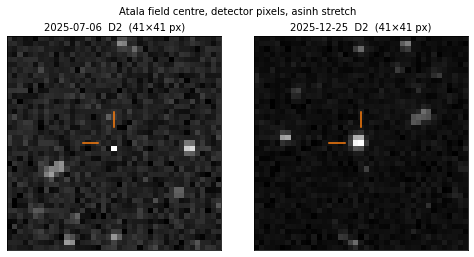

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
for ax, day in zip(axes, ["2025-07-06", "2025-12-25"]):
    lo, hi = np.percentile(cut[day], 1), np.max(cut[day])
    norm = ImageNormalize(vmin=lo, vmax=hi, stretch=AsinhStretch(0.02))
    ax.imshow(cut[day], origin="lower", cmap="gray", norm=norm)
    ax.plot([HALF - 6, HALF - 3], [HALF, HALF], color="tab:orange", lw=1.5)
    ax.plot([HALF, HALF], [HALF + 3, HALF + 6], color="tab:orange", lw=1.5)
    ax.set_title(f"{day}  D2  ({2 * HALF + 1}×{2 * HALF + 1} px)", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Atala field centre, detector pixels, asinh stretch", fontsize=10)
fig.tight_layout()

## 4. Name the source (IMCCE SkyBoT)

In [8]:
import warnings
from astroquery.exceptions import NoResultsWarning
from astroquery.imcce import Skybot

for day in VISITS:
    mid = Time(headers[day]["MJD-AVG"], format="mjd")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", NoResultsWarning)
        found = Skybot.cone_search(FIELD, 1 * u.arcmin, mid, location="500")
    if not len(found):
        print(f"{day} {mid.isot[:19]}  no catalogued object within 1′")
    for r in found:
        print(f"{day} {mid.isot[:19]}  ({r['Number']}) {r['Name']}  V={float(r['V']):.1f}  "
              f"{r['centerdist'].to(u.arcsec):.1f} from the centre")

2025-07-06 2025-07-06T11:42:21  no catalogued object within 1′
2025-12-25 2025-12-25T16:34:34  (152) Atala  V=13.8  1.9 arcsec from the centre


## 5. NEOSSat at CADC, as in the CSA tutorial

The same index (CAOM, the Argus TAP service) that Muninn asks: NEOSSat science observations
within 0.05° of Barnard's Star.

In [9]:
argus = pyvo.dal.TAPService("https://ws.cadc-ccda.hia-iha.nrc-cnrc.gc.ca/argus")
neossat = argus.run_sync("""
    SELECT o.observationID, p.time_bounds_lower, a.uri
    FROM caom2.Observation AS o
    JOIN caom2.Plane AS p ON o.obsID = p.obsID
    JOIN caom2.Artifact AS a ON a.planeID = p.planeID
    WHERE o.collection = 'NEOSSAT' AND o.intent = 'science' AND p.calibrationLevel >= 1
      AND a.productType = 'science'
      AND INTERSECTS(CIRCLE('ICRS', 269.452, 4.693, 0.05), p.position_bounds) = 1
""", maxrec=100000).to_table()
years = sorted({Time(t, format="mjd").datetime.year for t in neossat["time_bounds_lower"]})
print(f"{len(set(neossat['observationID']))} distinct NEOSSat observations, years {years}")

572 distinct NEOSSat observations, years [2019]


OBJECT   = BarnardStar
DATE-OBS = 2019-10-13T01:26:36.103
EXPOSURE = 1.1006
DATASEC  = [473:728,1:256]
sky WCS keywords: none


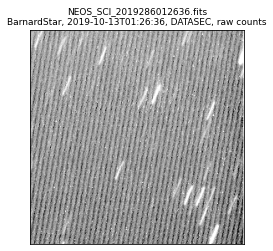

In [10]:
neossat.sort("time_bounds_lower")
uri = neossat["uri"][0]
with fits.open(f"https://ws-uv.canfar.net/minoc/files/{uri}", cache=False) as nh:
    raw = nh[0].data.astype(float)
    hdr = nh[0].header
for key in ("OBJECT", "DATE-OBS", "EXPOSURE", "DATASEC"):
    print(f"{key:9}= {hdr[key]}")
print("sky WCS keywords:", [k for k in ("CTYPE1", "CRVAL1", "CD1_1", "PC1_1") if k in hdr] or "none")

x0, x1 = (int(v) for v in hdr["DATASEC"].strip("[]").split(",")[0].split(":"))
data = raw[:, x0 - 1:x1]
fig, ax = plt.subplots(figsize=(3.6, 3.6))
norm = ImageNormalize(data, interval=ZScaleInterval(), stretch=AsinhStretch(0.1))
ax.imshow(data, origin="lower", cmap="gray", norm=norm)
ax.set_title(f"{uri.split('/')[-1]}\n{hdr['OBJECT']}, {hdr['DATE-OBS'][:19]}, DATASEC, raw counts", fontsize=9)
ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

These are level-1 frames: raw counts with the overscan strip still attached and a commanded
pointing in the header, but no sky WCS. Placing them on Muninn's grid would mean solving each
frame's astrometry first, which is why Muninn shows NEOSSat as a count of observations and a
raw preview rather than reprojecting it.

## 6. Summary

In [11]:
for h in hduls.values():
    h.close()

counts_ok = all(
    int(np.count_nonzero(flags[day] & (1 << bit))) == headers[day].get(f"L2 N_{name}")
    for day in flags for name, bit in BITS.items())
print("FLAGS bit counts vs header totals:", "all match" if counts_ok else "some differ (see section 2)")
print(f"6 Jul centre pixel: FLAGS {hex(int(jflag[py, px]))}, {jul[py, px] / np.median(neigh):.1f}× its neighbours")
for (day, masked), theirs in MUNINN.items():
    ours = results[(day, masked)]
    print(f"SNR {day} {'masked' if masked else 'unmasked'}: {ours:.1f} here, {theirs} in Muninn "
          f"({ours / theirs:.2f}×)")
print(f"NEOSSat at Barnard's Star: {len(set(neossat['observationID']))} observations (Muninn: 572)")

FLAGS bit counts vs header totals: all match
6 Jul centre pixel: FLAGS 0x45, 11.2× its neighbours
SNR 2025-12-25 unmasked: 425.4 here, 374.3 in Muninn (1.14×)
SNR 2025-07-06 unmasked: 168.6 here, 140 in Muninn (1.20×)
SNR 2025-07-06 masked: 2.0 here, 1.2 in Muninn (1.68×)
NEOSSat at Barnard's Star: 572 observations (Muninn: 572)


What matched: the FLAGS bit counts (so Muninn's Rice decoder and astropy's agree on every
pixel total the pipeline states), the 6 Jul pixel and its flags, Atala as the 25 Dec source,
and the NEOSSat count.

What did not match exactly: the signal-to-noise. Here it is 10–20 % higher for the two bright
cases, and 2.0 against 1.2 for the masked pixel. The rule is the same, but this notebook takes
the peak from a detector pixel, while Muninn takes it from its resampled grid (2.8″ samples
over 6.15″ pixels, bilinear), which spreads a one-pixel peak over its neighbours and so reads
lower; that is the likely cause of most of the gap, not checked pixel by pixel here. The masked case is noise in both: here a flagged pixel is simply left out, while Muninn
fills it from its nearest good neighbour. Both readings tell the same story: Atala stands far
above the sky on 25 Dec, and the 6 Jul "flash" disappears once the flagged pixel is masked.